In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter


In [2]:
gt_path = '../train_data/train_gt.csv'
wl_path = '../train_data/wavelengths.csv'


gt_df = pd.read_csv(gt_path)
wave_lengths = pd.read_csv(wl_path)

In [ ]:
#Loading example file, gaining insights about the data

img_no = 1200

path = f'../train_data/train_data/{img_no}.npz'

#axis 0 - band index, 1 - spectral image height, 2 - spectral image width
with np.load(path) as npz:
    spectral_arr = np.ma.MaskedArray(**npz)

bands, height, width = spectral_arr.shape

print(f'Bands = {bands}, height = {height}, width = {width}')
print(f'Data type: {spectral_arr.dtype}')
print(f'Max val = {spectral_arr.max()}, min val = {spectral_arr.min()}')



Bands = 150, height = 107, width = 101
Data type: int16
Max val = 4901, min val = 278


In [ ]:
#Plotting with & without binary mask
fig, ax = plt.subplots(2,2, figsize=(8,8))

ax[0,0].imshow(spectral_arr[0,:,:].data)
ax[0,1].imshow(spectral_arr[0,:,:])

ax[1,0].imshow(spectral_arr[149,:,:].data)
ax[1,1].imshow(spectral_arr[149,:,:])

plt.suptitle(f'Band 0 vs band 149 of spectral image {img_no}.npz')
plt.show()

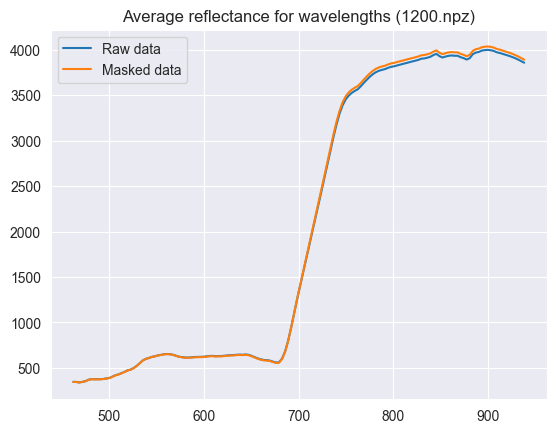

In [6]:
#Plotting spectral reflectance of the example image
spectral_reflectances_masked = [spectral_arr[i,:,:].mean() for i in range(bands)]
spectral_reflectances_raw = [spectral_arr[i,:,:].data.mean() for i in range(bands)]

plt.plot(wave_lengths['wavelength'], spectral_reflectances_raw, label = "Raw data")
plt.plot(wave_lengths['wavelength'], spectral_reflectances_masked, label = "Masked data")
plt.title(f'Average reflectance for wavelengths ({img_no}.npz)')
plt.legend()
plt.show()

In [ ]:
#Calculating correlation between bands of the example image
image_flat = spectral_arr.reshape(bands, -1)
corr = np.corrcoef(image_flat)

plt.imshow(corr, cmap='viridis')
plt.colorbar()
plt.xticks(range(0,bands+1,25))
plt.yticks(range(0,bands+1,25))
plt.show()

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [9]:
#Preparing data for PCA (of the example image)
X = spectral_arr.data.reshape(bands, -1).T #(width * height, bands) transposed

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_transformed = pca.fit_transform(X_scaled)

In [ ]:
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [11]:
#first principal component
pc1 = pca.components_[0]
pc2 = pca.components_[1]

print(pca.components_.shape)

(2, 150)


In [11]:
#PCA for almost whole dataset (step = 10 - every 10th image)
X_total = []

for i in range(0,1701,10):
    with np.load(f'../train_data/train_data/{i}.npz') as npz:
        arr = np.ma.MaskedArray(**npz)

    x = arr.data.reshape(arr.shape[0], -1).T #(width * height, bands)
    mask = arr.mask.reshape(arr.shape[0], -1).T

    #including binary mask
    x_valid = x[~mask.any(axis=1)]
    X_total.append(x_valid)

X_total = np.vstack(X_total)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_total)

pca = PCA(n_components=10)
X_transformed = pca.fit_transform(X_scaled)

print(pca.explained_variance_ratio_.cumsum())


[0.67130931 0.9902943  0.99610577 0.99892918 0.9991785  0.99935485
 0.99944833 0.99951335 0.99957001 0.99961949]


In [ ]:
#Plotting variance ratios of every Prinicpal Component - there are 2 PC's that explain >= 95% of the data variance
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [12]:
def plot_pca_loadings(pca_model, wavelengths=None, n_components=3):
    """
    Visualizes PCA loadings (eigenvectors) to show band influence.
    """
    loadings = pca_model.components_

    n_bands = loadings.shape[1]

    if wavelengths is None:
        x_axis = np.arange(n_bands)
        x_label = "Band Index"
    else:
        if len(wavelengths) != n_bands:
            print(f"WARNING: Length of wavelengths list ({len(wavelengths)}) does not match number of bands in PCA ({n_bands}). Using indices.")
            x_axis = np.arange(n_bands)
            x_label = "Band Index"
        else:
            x_axis = wavelengths
            x_label = "Wavelength [nm]"

    plt.figure(figsize=(14, 6))

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for i in range(n_components):
        c = colors[i % len(colors)]
        plt.plot(x_axis, loadings[i, :], label=f'PC {i+1}', color=c, linewidth=1.5)

        max_idx = np.argmax(np.abs(loadings[i, :]))
        plt.scatter(x_axis[max_idx], loadings[i, max_idx], color=c, s=50, zorder=5)

    plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)

    plt.title(f'PCA Loadings: Band Influence on First {n_components} Components', fontsize=14)
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Loading Value (Eigenvector Coefficient)', fontsize=12)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
plot_pca_loadings(pca, wavelengths=None, n_components=2)

Calculating avarage spectrum for each image

In [15]:
X_means = []
valid_indices = []


for idx, row in gt_df.iterrows():
    img_id = int(row.get('sample_index', idx))

    path = f'../train_data/train_data/{img_id}.npz'

    try:
        with np.load(path) as npz:
            arr = np.ma.MaskedArray(**npz)
        mean_spectrum = arr.mean(axis=(1,2))
        if np.ma.is_masked(mean_spectrum):
            continue
        X_means.append(mean_spectrum.data)
        valid_indices.append(idx)

    except FileNotFoundError:
        print(f"File not found for index {img_id}")
        continue

X_means = np.array(X_means)
gt_df_clean = gt_df.loc[valid_indices].reset_index(drop=True)
print({X_means.shape})
print( {len(gt_df_clean)})

{(1732, 150)}
{1732}


In [17]:
target_cols = ['P', 'K', 'Mg', 'pH']
if 'wave_lengths' in locals():
    wl_axis = wave_lengths['wavelength'].values
    index_name = 'Wavelength [nm]'
else:
    wl_axis = np.arange(X_means.shape[1])
    index_name = 'Band Index'
correlations = {col: [] for col in target_cols}
for band_idx in range(X_means.shape[1]):
    band_vals = X_means[:, band_idx]

    for target in target_cols:
        if target not in gt_df_clean.columns:
            continue

        y_vals = gt_df_clean[target].values
        if np.std(band_vals) == 0 or np.std(y_vals) == 0:
            corr = 0 #
        else:
            corr, _ = spearmanr(band_vals, y_vals)
        correlations[target].append(corr)


In [18]:
feature_corr_matrix = gt_df_clean[target_cols].corr(method='spearman')
print(feature_corr_matrix)

           P         K        Mg        pH
P   1.000000  0.380047 -0.146342  0.137364
K   0.380047  1.000000  0.252113  0.128206
Mg -0.146342  0.252113  1.000000 -0.013374
pH  0.137364  0.128206 -0.013374  1.000000


In [ ]:
plt.figure(figsize=(12, 8))

colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown']

for i, target in enumerate(target_cols):
    if target in correlations and len(correlations[target]) > 0:


        current_color = colors[i % len(colors)]

        plt.plot(wl_axis, correlations[target], label=target, color=current_color, linewidth=2)

plt.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.5)
plt.axhline(-0.5, color='gray', linestyle=':', alpha=0.5)

plt.title('spearman Correlation: Mean Spectrum vs Soil Properties', fontsize=16)
plt.xlabel('Wavelength [nm]', fontsize=12)
plt.ylabel('spearman Correlation Coefficient (r)', fontsize=12)
plt.legend(fontsize=12, loc='upper right')
plt.grid(True, alpha=0.3)

plt.ylim(-1.0, 1.0)
plt.tight_layout()
plt.show()

In [ ]:
def preprocess_dataset_with_gauss_sg(gt_df, data_dir, target_cols=['P', 'K', 'Mg', 'pH']):
        X_features = []
        y_labels = []
        valid_indices = []
        sigma_params = (0, 2, 2) #denoising on all axes except the spectral channels
        sg_window = 11
        sg_poly = 2
        sg_deriv = 1

        print(f"Method: Gauss(sigma={sigma_params}) -> Mean -> SavGol(deriv={sg_deriv})")
        for i, row in gt_df.iterrows():
            img_id = int(row.get('sample_index', i))
            path = f'{data_dir}/{img_id}.npz'

            try:
                with np.load(path) as npz:
                    spectral_arr = np.ma.MaskedArray(**npz)


                spectral_arr_gauss = spectral_arr.copy()
                blurred_data = gaussian_filter(spectral_arr.data, sigma=sigma_params)
                spectral_arr_gauss.data[:] = blurred_data

                mean_spectrum = spectral_arr_gauss.mean(axis=(1, 2))
                if np.ma.is_masked(mean_spectrum):
                    continue
                mean_spectrum_data = mean_spectrum.data

                derivative_sg = savgol_filter(mean_spectrum_data, window_length=sg_window, polyorder=sg_poly, deriv=sg_deriv)



                X_features.append(derivative_sg)
                y_labels.append(row[target_cols].values)
                valid_indices.append(img_id)
            except Exception as e:
                print(f"Error {img_id}: {e}")
                continue
            if i > 0 and i % 100 == 0:
                print(f"   Processed {i} / {len(gt_df)}...")
        X = np.array(X_features)
        y = np.array(y_labels)

        print(X.shape)
        return X, y, valid_indices

data_folder = '../train_data/train_data'
X_processed, y_all, indices = preprocess_dataset_with_gauss_sg(gt_df, data_folder)

In [33]:
def rfe_selection(X, y, n_features_to_select=50, step=5):
    estimator = RandomForestRegressor(
        n_estimators=100,
        n_jobs=-1,
        random_state=42
    )
    selector = RFE(
        estimator=estimator,
        n_features_to_select=n_features_to_select,
        step=step,
    )

    selector.fit(X, y)

    X_selected = selector.transform(X)
    mask = selector.get_support()
    selected_indices = np.where(mask)[0]

    print(X_selected.shape)

    return X_selected, selected_indices, selector

In [36]:
N_FEATURES = 25
STEP_SIZE = 5

X_rfe, rfe_indices, rfe_model = rfe_selection(
    X_processed,
    y_all,
    n_features_to_select=N_FEATURES,
    step=STEP_SIZE
)

rfe_indices.sort()
print(f"\nIndices of selected bands:\n{rfe_indices}")

(1732, 25)

Indices of selected bands:
[  0   5  11  18  27  41  51  53  58  64  65  66  67  94  98 109 117 122
 125 130 134 136 137 138 149]


In [25]:
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.metrics import r2_score as R2, mean_squared_error as MSE, mean_absolute_error as MAE
SEED = 123

In [37]:
target_cols = ['P', 'K', 'Mg', 'pH']
models = {}
measures = {}


X_train, X_test, y_train, y_test = train_test_split(X_rfe, y_all, test_size=0.2, random_state=SEED)

param_grid_rf = {
    'n_estimators': [100, 200, 300, 400, 500, 600, 700],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features' : ['log2','sqrt']
}

for i, soil_param in enumerate(target_cols):
    #subsetting y_train, y_test to obtain single soil param each iteration
    y_train_param = y_train[:,i]
    y_test_param = y_test[:,i]

    rf = RandomForestRegressor(random_state=SEED, n_jobs=-1)

    rand_search = RandomizedSearchCV(estimator=rf, param_distributions=param_grid_rf, 
                                     n_iter=10, cv=5, scoring='neg_mean_squared_error', random_state=SEED, n_jobs=-1)
    
    rand_search.fit(X_train, y_train_param)

    best_model = rand_search.best_estimator_
    y_pred = best_model.predict(X_test)

    r2 = R2(y_test_param, y_pred)
    mse = MSE(y_test_param, y_pred)
    rmse = np.sqrt(mse)
    mae = MAE(y_test_param, y_pred)

    models[soil_param] = best_model
    measures[soil_param] = {'R2':r2, 'MAE':mae, 'MSE':mse, 'RMSE':rmse}

    print(f'Best params for [{soil_param}] parameter: {rand_search.best_params_}\n')
    print(f'[{soil_param}] parameter model scorings - R2: {r2:.4f}, MAE: {mae:.4f}, MSE: {mse:.4f} RMSE: {rmse:.4f}\n')


print(measures)


Best params for [P] parameter: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 30}

[P] parameter model scorings - R2: 0.0272, MAE: 20.0775, MSE: 898.6625 RMSE: 29.9777

Best params for [K] parameter: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 30}

[K] parameter model scorings - R2: 0.0751, MAE: 41.4349, MSE: 3157.0577 RMSE: 56.1877

Best params for [Mg] parameter: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

[Mg] parameter model scorings - R2: 0.0847, MAE: 27.3033, MSE: 1378.9947 RMSE: 37.1348

Best params for [pH] parameter: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

[pH] parameter model scorings - R2: 0.1633, MAE: 0.1845, MSE: 0.0593 RMSE: 0.2435

{'P': {'R2': 0.027183438034501628, 'MAE': 20.077469852897092, 'MSE': 898.6624807164792

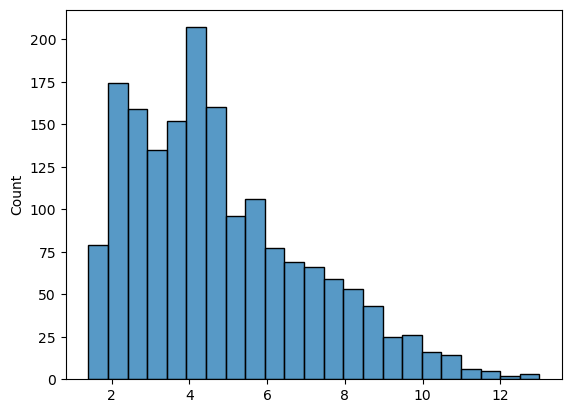

In [40]:
sns.histplot(X_rfe.std(axis=1))
plt.show()

In [43]:
y_all.shape


(1732, 4)